In [22]:
import sys
sys.path.append('..')

import cv2
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf

from src.grid_detection import find_grid_corners, warp_grid
from src.cell_extraction import split_cells

model = tf.keras.models.load_model('../models/digit_classifier.keras')
class_names = ['1', '2', '3', '4', '5', '6', '7', '8', '9', 'empty']

# Force the model to build its call graph
dummy_input = np.zeros((1, 28, 28, 1), dtype='float32')
_ = model(dummy_input)

model.summary()

Model: "sequential_3"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ sequential_2 (Sequential)       │ (None, 28, 28, 1)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 28, 28, 32)     │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_3           │ (None, 28, 28, 32)     │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (None, 14, 14, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_4 (Conv2D)               │ (None, 14, 14, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_4           │ (None, 14, 14, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_4 (MaxPooling2D)  │ (None, 7, 7, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_5 (Conv2D)               │ (None, 7, 7, 128)      │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_5           │ (None, 7, 7, 128)      │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_5 (MaxPooling2D)  │ (None, 3, 3, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_1 (Flatten)             │ (None, 1152)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 128)            │       147,584 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 726,432 (2.77 MB)

 Trainable params: 241,994 (945.29 KB)

 Non-trainable params: 448 (1.75 KB)

 Optimizer params: 483,990 (1.85 MB)

In [23]:
def print_layers(layers, indent=0):
    for layer in layers:
        print('  ' * indent + f"{layer.name} ({type(layer).__name__})")
        if hasattr(layer, 'layers'):
            print_layers(layer.layers, indent + 1)

print_layers(model.layers)

sequential_2 (Sequential)
  random_rotation_1 (RandomRotation)
  random_zoom_1 (RandomZoom)
  random_translation_1 (RandomTranslation)
conv2d_3 (Conv2D)
batch_normalization_3 (BatchNormalization)
max_pooling2d_3 (MaxPooling2D)
conv2d_4 (Conv2D)
batch_normalization_4 (BatchNormalization)
max_pooling2d_4 (MaxPooling2D)
conv2d_5 (Conv2D)
batch_normalization_5 (BatchNormalization)
max_pooling2d_5 (MaxPooling2D)
flatten_1 (Flatten)
dense_2 (Dense)
dropout_1 (Dropout)
dense_3 (Dense)


In [24]:
def find_last_conv_layer(model):
    def search(layers):
        for layer in reversed(layers):
            if hasattr(layer, 'layers') and len(layer.layers) > 0:
                result = search(layer.layers)
                if result:
                    return result
            elif isinstance(layer, tf.keras.layers.Conv2D):
                return layer.name
        return None

    name = search(model.layers)
    if name is None:
        raise ValueError("No Conv2D layer found in model")
    return name

last_conv_layer_name = find_last_conv_layer(model)
print("Using layer:", last_conv_layer_name)

Using layer: conv2d_5


In [25]:
def make_gradcam_heatmap(img_array, model, last_conv_layer_name, pred_index=None):
    img_tensor = tf.convert_to_tensor(img_array)

    def forward_and_capture(x, layers, target_name):
        conv_output = None
        for layer in layers:
            if hasattr(layer, 'layers') and len(layer.layers) > 0:
                x, nested_conv = forward_and_capture(x, layer.layers, target_name)
                if nested_conv is not None:
                    conv_output = nested_conv
            else:
                x = layer(x)
                if layer.name == target_name:
                    conv_output = x
        return x, conv_output

    with tf.GradientTape() as tape:
        tape.watch(img_tensor)
        preds, conv_output = forward_and_capture(img_tensor, model.layers, last_conv_layer_name)
        tape.watch(conv_output)
        if pred_index is None:
            pred_index = tf.argmax(preds[0])
        class_channel = preds[:, pred_index]

    grads = tape.gradient(class_channel, conv_output)
    pooled_grads = tf.reduce_mean(grads, axis=(0, 1, 2))

    conv_output = conv_output[0]
    heatmap = conv_output @ pooled_grads[..., tf.newaxis]
    heatmap = tf.squeeze(heatmap)

    heatmap = tf.maximum(heatmap, 0) / (tf.math.reduce_max(heatmap) + 1e-8)
    return heatmap.numpy(), int(pred_index), float(preds[0][pred_index])

In [26]:
def overlay_heatmap(cell_img, heatmap, alpha=0.5, size=28):
    heatmap_resized = cv2.resize(heatmap, (size, size))
    heatmap_uint8 = np.uint8(255 * heatmap_resized)
    heatmap_color = cv2.applyColorMap(heatmap_uint8, cv2.COLORMAP_JET)

    cell_bgr = cv2.cvtColor(cell_img, cv2.COLOR_GRAY2BGR) if len(cell_img.shape) == 2 else cell_img
    cell_bgr = cv2.resize(cell_bgr, (size, size))

    overlaid = cv2.addWeighted(cell_bgr, 1 - alpha, heatmap_color, alpha, 0)
    return overlaid


In [27]:
def preprocess_cell(cell_img, size=28):
    _, thresh = cv2.threshold(cell_img, 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU)
    resized = cv2.resize(thresh, (size, size))
    normalized = resized.astype('float32') / 255.0
    return normalized.reshape(1, size, size, 1), resized

In [28]:
img = cv2.imread('../data/raw/sample2.png')
corners = find_grid_corners(img)
warped, M = warp_grid(img, corners)
warped_gray = cv2.cvtColor(warped, cv2.COLOR_BGR2GRAY)
cells = split_cells(warped_gray)

print(f"Extracted {len(cells)} cells")

Extracted 81 cells


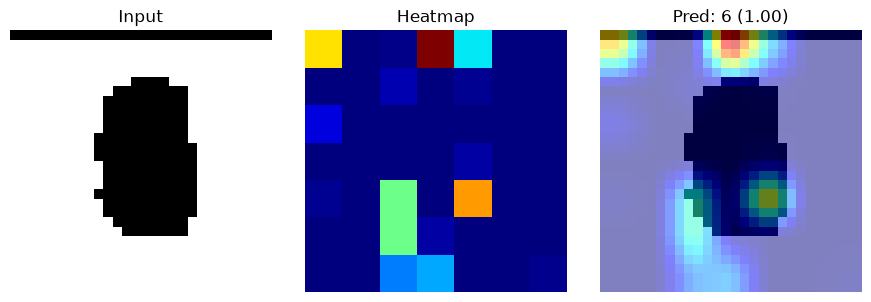

In [29]:
test_cell = cells[0]  # pick any cell with a digit
input_tensor, resized_cell = preprocess_cell(test_cell)

heatmap, pred_idx, confidence = make_gradcam_heatmap(input_tensor, model, last_conv_layer_name)
label = class_names[pred_idx]

overlaid = overlay_heatmap(resized_cell, heatmap)

fig, axes = plt.subplots(1, 3, figsize=(9, 3))
axes[0].imshow(resized_cell, cmap='gray'); axes[0].set_title('Input'); axes[0].axis('off')
axes[1].imshow(heatmap, cmap='jet'); axes[1].set_title('Heatmap'); axes[1].axis('off')
axes[2].imshow(cv2.cvtColor(overlaid, cv2.COLOR_BGR2RGB)); axes[2].set_title(f'Pred: {label} ({confidence:.2f})'); axes[2].axis('off')
plt.tight_layout()

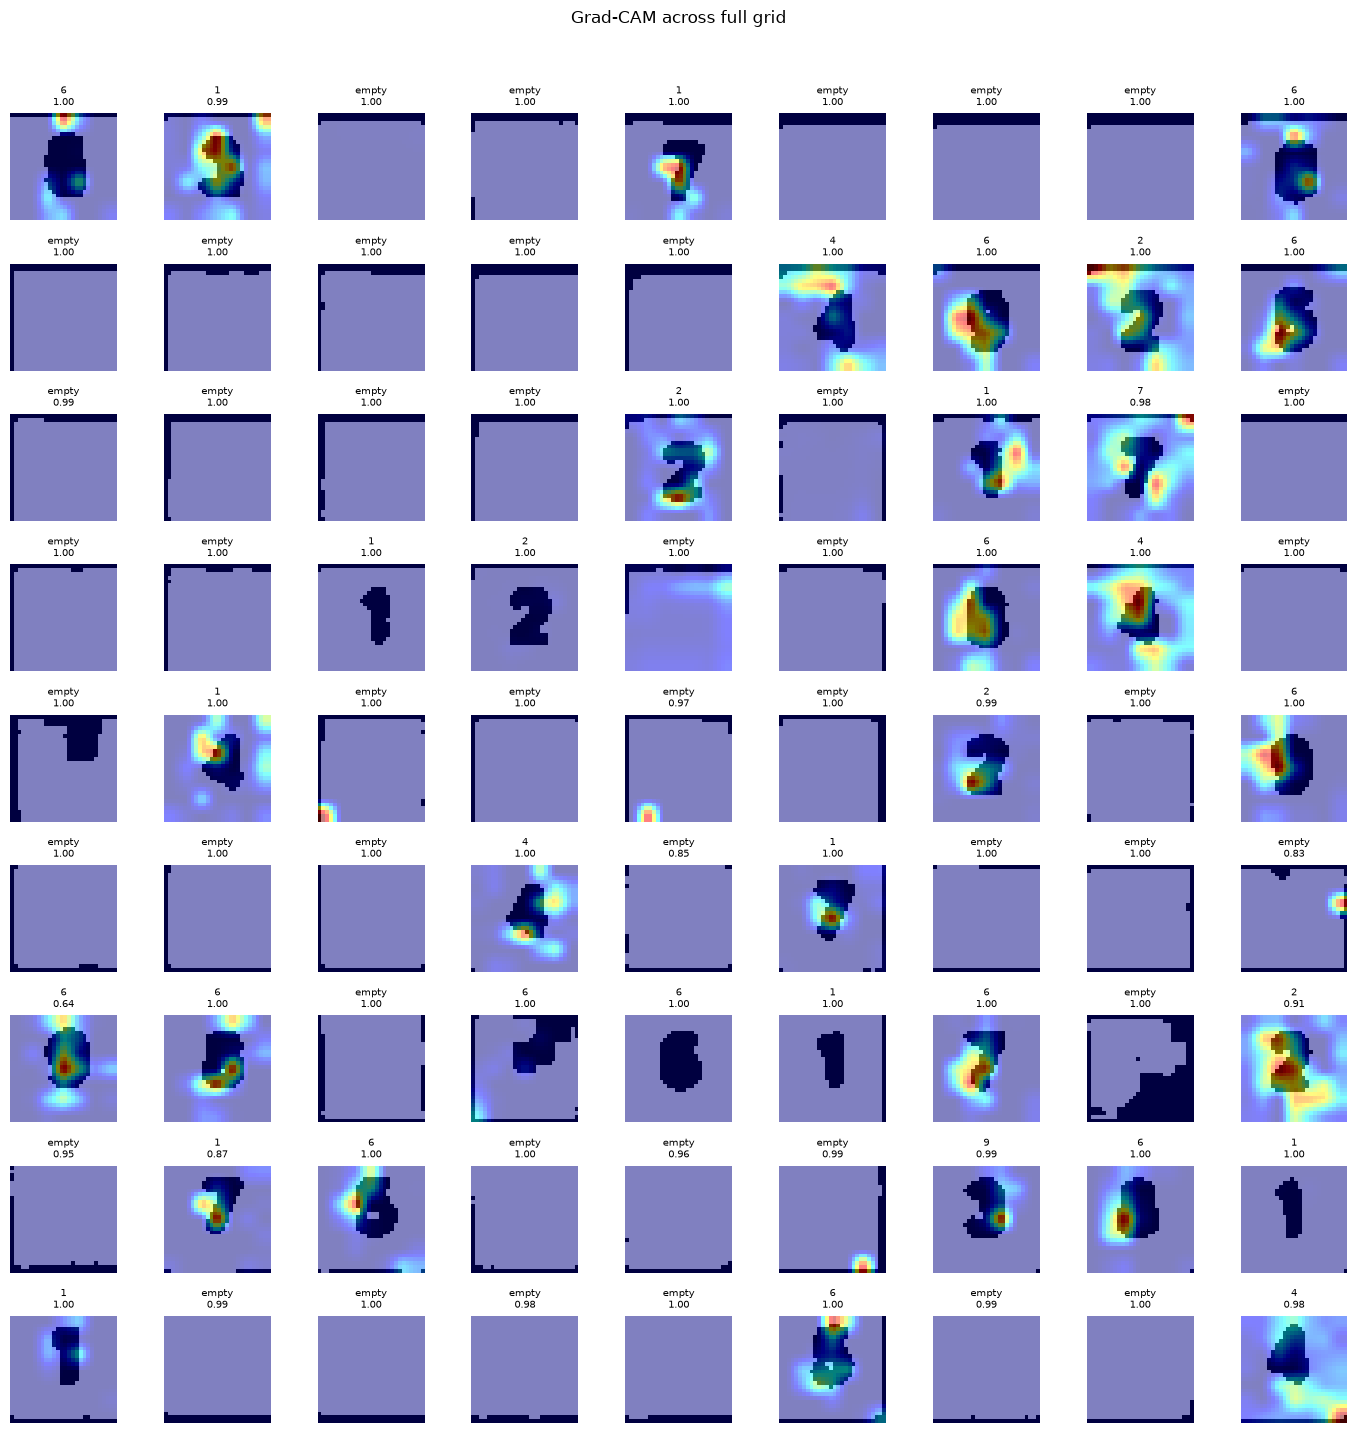

In [30]:
fig, axes = plt.subplots(9, 9, figsize=(14, 14))

for row in range(9):
    for col in range(9):
        cell = cells[row * 9 + col]
        input_tensor, resized_cell = preprocess_cell(cell)
        heatmap, pred_idx, confidence = make_gradcam_heatmap(input_tensor, model, last_conv_layer_name)
        label = class_names[pred_idx]
        overlaid = overlay_heatmap(resized_cell, heatmap)

        ax = axes[row][col]
        ax.imshow(cv2.cvtColor(overlaid, cv2.COLOR_BGR2RGB))
        ax.set_title(f'{label}\n{confidence:.2f}', fontsize=7)
        ax.axis('off')

plt.suptitle('Grad-CAM across full grid', y=1.02)
plt.tight_layout()

Cells worth inspecting closely (low confidence):



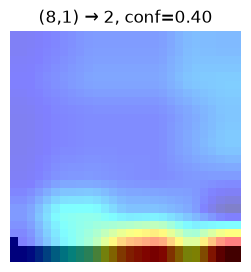

In [31]:
threshold = 0.7
print("Cells worth inspecting closely (low confidence):\n")

for row in range(9):
    for col in range(9):
        cell = cells[row * 9 + col]
        input_tensor, resized_cell = preprocess_cell(cell)
        heatmap, pred_idx, confidence = make_gradcam_heatmap(input_tensor, model, last_conv_layer_name)
        label = class_names[pred_idx]

        if confidence < threshold:
            overlaid = overlay_heatmap(resized_cell, heatmap)
            plt.figure(figsize=(3, 3))
            plt.imshow(cv2.cvtColor(overlaid, cv2.COLOR_BGR2RGB))
            plt.title(f'({row},{col}) → {label}, conf={confidence:.2f}')
            plt.axis('off')
            plt.show()